# TrustXRay — 03. Uncertainty with Monte Carlo Dropout

**Problem found in notebook 02:** the model gives a probability, but it does not tell us **how sure it is**. Its probabilities are also not calibrated (decision threshold = 0.043 instead of 0.5).

**Goal of this notebook:**
1. Measure the uncertainty of each prediction with **Monte Carlo Dropout** (Gal & Ghahramani, 2016).
2. Check the key hypothesis: **are the model's errors the cases where it is uncertain?**
3. Build a **referral rule**: uncertain cases are sent to a radiologist instead of being decided by the AI.

> ⚠️ In Colab: **Runtime → Change runtime type → T4 GPU**. The trained model from notebook 02 must be in Google Drive (`MyDrive/TrustXRay/resnet18_baseline.pt`).

In [1]:
!pip install -q medmnist

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 5.9 MB/s eta 0:00:00


In [2]:
import os, json
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import transforms, models
from medmnist import PneumoniaMNIST
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

SIZE = 224
DATA_DIR = "./data"
FIG_DIR = "./figures"
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_DIR = "/content/drive/MyDrive/TrustXRay"
except ImportError:
    SAVE_DIR = "./models"
MODEL_PATH = os.path.join(SAVE_DIR, "resnet18_baseline.pt")
assert os.path.exists(MODEL_PATH), f"Model not found: {MODEL_PATH} — run notebook 02 first"
print("Model:", MODEL_PATH)

Device: cuda
Mounted at /content/drive
Model: /content/drive/MyDrive/TrustXRay/resnet18_baseline.pt


## 1. Load the trained model and the data

In [3]:
def build_model(dropout=0.3):
    model = models.resnet18(weights=None)
    model.fc = nn.Sequential(nn.Dropout(p=dropout), nn.Linear(model.fc.in_features, 1))
    return model

model = build_model().to(DEVICE)
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model.eval()

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
eval_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)])

val_ds  = PneumoniaMNIST(split="val",  transform=eval_tf, download=True, size=SIZE, as_rgb=True, root=DATA_DIR)
test_ds = PneumoniaMNIST(split="test", transform=eval_tf, download=True, size=SIZE, as_rgb=True, root=DATA_DIR)
val_loader  = DataLoader(val_ds,  batch_size=64, shuffle=False, num_workers=2)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False, num_workers=2)
print(f"val={len(val_ds)}  test={len(test_ds)}")

100%|██████████| 214M/214M [03:08<00:00, 1.14MB/s]


val=524  test=624


## 2. Monte Carlo Dropout — the idea

Normally, dropout is **switched off** at prediction time: the model always gives the same answer.

With **Monte Carlo Dropout**, we keep dropout **switched on** and pass the same X-ray **T = 30 times**. Each pass randomly removes 30% of the neurons of the last layer, so each pass is like asking a slightly different "expert".

- If the 30 answers agree → the model is **sure**.
- If the answers are spread out, some above and some below the decision threshold → the model **hesitates**.

**Implementation detail:** our dropout is only in the last layer. So we compute the image features **once**, then apply the last layer 30 times. This gives exactly the same result as 30 full passes, but about 30× faster.

In [4]:
T = 30  # number of stochastic forward passes

feature_extractor = nn.Sequential(*list(model.children())[:-1])  # everything except the head
head = model.fc                                                   # Dropout + Linear

@torch.no_grad()
def mc_dropout_logits(loader, T=T):
    feature_extractor.eval()
    head.train()                      # keep dropout ACTIVE in the head
    all_logits, all_labels = [], []
    for x, y in loader:
        feats = feature_extractor(x.to(DEVICE)).flatten(1)            # [B, 512]
        logits = torch.stack([head(feats).squeeze(1) for _ in range(T)], dim=1)  # [B, T]
        all_logits.append(logits.cpu()); all_labels.append(y.ravel())
    head.eval()
    return torch.cat(all_logits).numpy(), torch.cat(all_labels).numpy()

val_logits, val_labels = mc_dropout_logits(val_loader)
test_logits, test_labels = mc_dropout_logits(test_loader)
print("val logits:", val_logits.shape, " test logits:", test_logits.shape)

val logits: (524, 30)  test logits: (624, 30)


## 3. From 30 answers to one decision + one uncertainty score

For each X-ray we compute:
- **mean logit** → the decision (pneumonia if above the threshold chosen on validation)
- **votes** → how many of the 30 passes say "pneumonia" (easy to explain: *"28 / 30 passes say pneumonia"*)
- **uncertainty score z** = distance between the mean logit and the decision threshold, measured in standard deviations of the 30 answers:

$$z = \frac{|\text{mean logit} - \text{threshold}|}{\text{std of the 30 logits}}$$

**Small z → the answers are close to the decision boundary → uncertain.** Large z → far from the boundary → confident.

We work with logits (before the sigmoid) because the probabilities are not calibrated (see notebook 02).

In [5]:
def summarize(logits, thr_logit):
    mean = logits.mean(axis=1)
    std = logits.std(axis=1) + 1e-6
    votes = (logits >= thr_logit).sum(axis=1)          # passes saying "pneumonia"
    pred = (mean >= thr_logit).astype(int)
    z = np.abs(mean - thr_logit) / std
    prob = 1 / (1 + np.exp(-mean))
    return {"mean": mean, "std": std, "votes": votes, "pred": pred, "z": z, "prob": prob}

# Decision threshold chosen on VALIDATION (Youden), in logit space
fpr, tpr, thr = roc_curve(val_labels, val_logits.mean(axis=1))
THR_LOGIT = float(thr[np.argmax(tpr - fpr)])
print(f"Decision threshold: logit = {THR_LOGIT:.3f}  (probability = {1 / (1 + np.exp(-THR_LOGIT)):.3f})")

val_s = summarize(val_logits, THR_LOGIT)
test_s = summarize(test_logits, THR_LOGIT)
test_s["correct"] = (test_s["pred"] == test_labels)
val_s["correct"] = (val_s["pred"] == val_labels)
print(f"Test errors: {(~test_s['correct']).sum()} / {len(test_labels)}")

Decision threshold: logit = -3.087  (probability = 0.044)
Test errors: 31 / 624


## 4. The key question: are errors the uncertain cases?

If MC Dropout works, wrong predictions should have a **smaller z** (more uncertainty) than correct ones.

Median z — correct predictions: 23.0   |   errors: 13.3
AUROC of the uncertainty score for detecting errors: 0.795


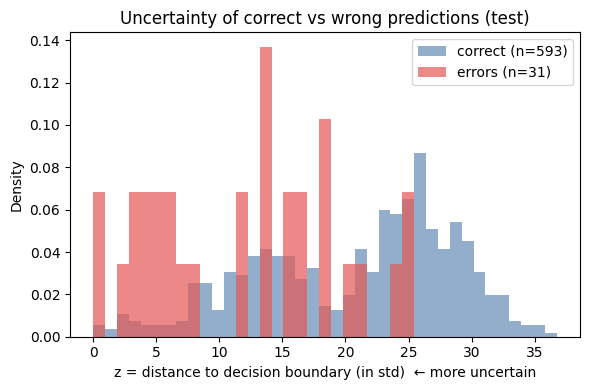

In [6]:
z_ok = test_s["z"][test_s["correct"]]
z_err = test_s["z"][~test_s["correct"]]
print(f"Median z — correct predictions: {np.median(z_ok):.1f}   |   errors: {np.median(z_err):.1f}")

# How well does uncertainty detect errors? (AUROC: 1 = perfect, 0.5 = random)
err_auc = roc_auc_score(~test_s["correct"], -test_s["z"])
print(f"AUROC of the uncertainty score for detecting errors: {err_auc:.3f}")

plt.figure(figsize=(6, 4))
bins = np.linspace(0, np.percentile(test_s["z"], 99), 40)
plt.hist(z_ok, bins=bins, alpha=0.6, density=True, label=f"correct (n={len(z_ok)})", color="#4C78A8")
plt.hist(z_err, bins=bins, alpha=0.7, density=True, label=f"errors (n={len(z_err)})", color="#E45756")
plt.xlabel("z = distance to decision boundary (in std)  ← more uncertain")
plt.ylabel("Density"); plt.title("Uncertainty of correct vs wrong predictions (test)")
plt.legend(); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/uncertainty_correct_vs_errors.png", dpi=150); plt.show()

## 5. Referral: what if the AI sends its most uncertain cases to a radiologist?

We sort the test X-rays from most uncertain to most confident, refer the top x% to a human, and measure the performance of the AI on the cases it keeps.

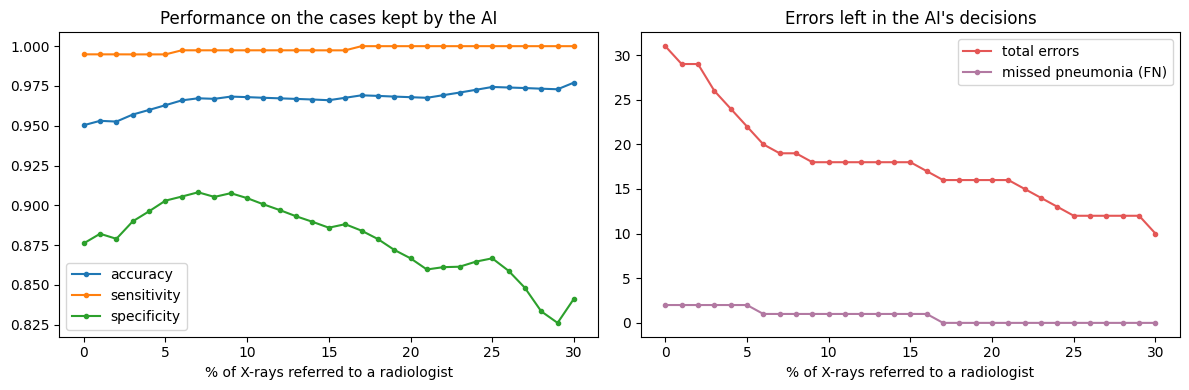

refer  0% → accuracy 0.950, sensitivity 0.995, specificity 0.876, errors left 31 (FN=2)
refer  5% → accuracy 0.963, sensitivity 0.995, specificity 0.903, errors left 22 (FN=2)
refer 10% → accuracy 0.968, sensitivity 0.997, specificity 0.904, errors left 18 (FN=1)
refer 20% → accuracy 0.968, sensitivity 1.000, specificity 0.867, errors left 16 (FN=0)


In [7]:
def metrics(labels, pred):
    tn, fp, fn, tp = confusion_matrix(labels, pred, labels=[0, 1]).ravel()
    return {"accuracy": (tp + tn) / max(len(labels), 1),
            "sensitivity": tp / max(tp + fn, 1), "specificity": tn / max(tn + fp, 1),
            "FN": int(fn), "FP": int(fp)}

order = np.argsort(test_s["z"])          # most uncertain first
rates = np.arange(0, 0.31, 0.01)
curve = []
for r in rates:
    keep = np.ones(len(order), bool); keep[order[:int(round(r * len(order)))]] = False
    curve.append(metrics(test_labels[keep], test_s["pred"][keep]))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(100 * rates, [c["accuracy"] for c in curve], "o-", ms=3, label="accuracy")
ax1.plot(100 * rates, [c["sensitivity"] for c in curve], "o-", ms=3, label="sensitivity")
ax1.plot(100 * rates, [c["specificity"] for c in curve], "o-", ms=3, label="specificity")
ax1.set_xlabel("% of X-rays referred to a radiologist"); ax1.set_title("Performance on the cases kept by the AI"); ax1.legend()
ax2.plot(100 * rates, [c["FN"] + c["FP"] for c in curve], "o-", ms=3, color="#E45756", label="total errors")
ax2.plot(100 * rates, [c["FN"] for c in curve], "o-", ms=3, color="#B279A2", label="missed pneumonia (FN)")
ax2.set_xlabel("% of X-rays referred to a radiologist"); ax2.set_title("Errors left in the AI's decisions"); ax2.legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/referral_curve.png", dpi=150); plt.show()

for r in [0, 0.05, 0.10, 0.20]:
    c = curve[int(round(r * 100))]
    print(f"refer {int(100 * r):2d}% → accuracy {c['accuracy']:.3f}, sensitivity {c['sensitivity']:.3f}, "
          f"specificity {c['specificity']:.3f}, errors left {c['FN'] + c['FP']} (FN={c['FN']})")

## 6. Fix the referral rule on validation, then apply it to test

To stay honest, the uncertainty cut-off is chosen on the **validation set** (refer ~10% of cases), then applied unchanged to the test set.

In [8]:
REFER_RATE = 0.10
Z_CUTOFF = float(np.quantile(val_s["z"], REFER_RATE))
print(f"Uncertainty cut-off (chosen on validation): z < {Z_CUTOFF:.2f} → refer to radiologist")

referred = test_s["z"] < Z_CUTOFF
kept = ~referred
errors = ~test_s["correct"]
print(f"\nTest: {referred.sum()} / {len(referred)} X-rays referred ({100 * referred.mean():.1f}%)")
print(f"Errors caught by referral: {(errors & referred).sum()} / {errors.sum()}")
print(f"Missed pneumonia caught:   {((test_s['pred'] == 0) & (test_labels == 1) & referred).sum()} / "
      f"{((test_s['pred'] == 0) & (test_labels == 1)).sum()}")

m_all = metrics(test_labels, test_s["pred"])
m_kept = metrics(test_labels[kept], test_s["pred"][kept])
print(f"\n{'':22s}{'all cases':>12s}{'AI-kept cases':>16s}")
for k in ["accuracy", "sensitivity", "specificity"]:
    print(f"{k:22s}{m_all[k]:12.3f}{m_kept[k]:16.3f}")
for k in ["FN", "FP"]:
    print(f"{k:22s}{m_all[k]:12d}{m_kept[k]:16d}")

Uncertainty cut-off (chosen on validation): z < 11.97 → refer to radiologist

Test: 105 / 624 X-rays referred (16.8%)
Errors caught by referral: 15 / 31
Missed pneumonia caught:   2 / 2

                         all cases   AI-kept cases
accuracy                     0.950           0.969
sensitivity                  0.995           1.000
specificity                  0.876           0.885
FN                               2               0
FP                              29              16


## 7. Look at examples: confident vs uncertain vs wrong

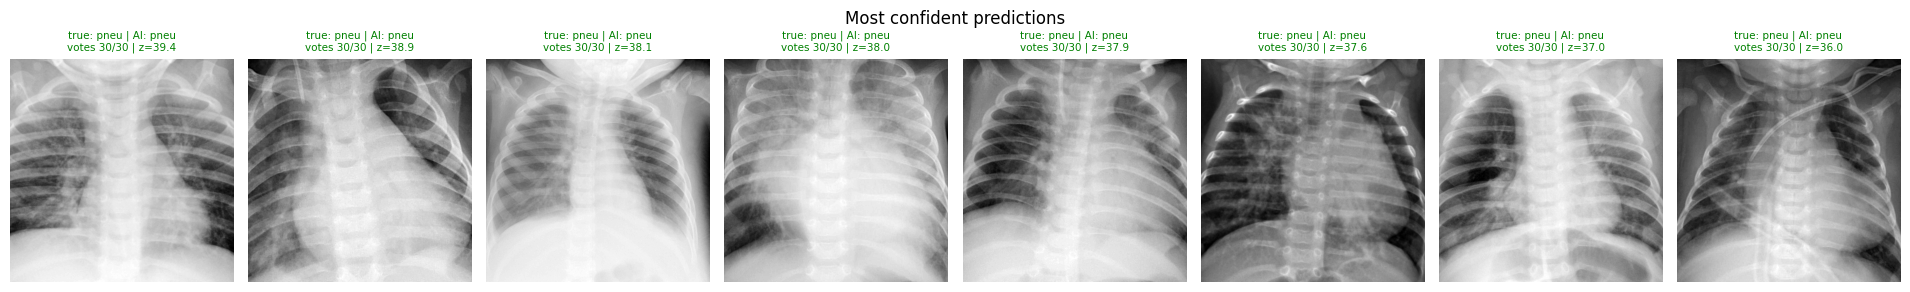

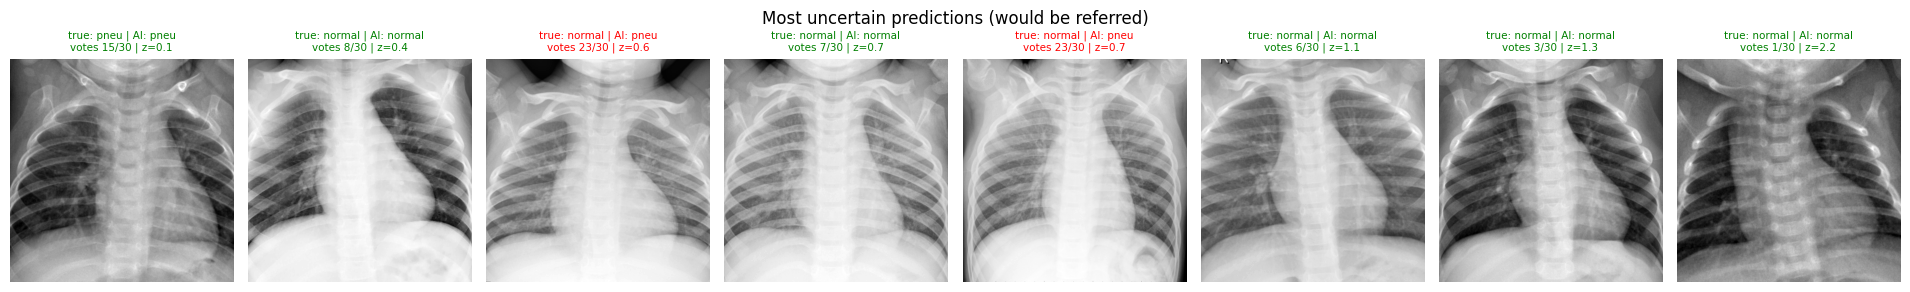

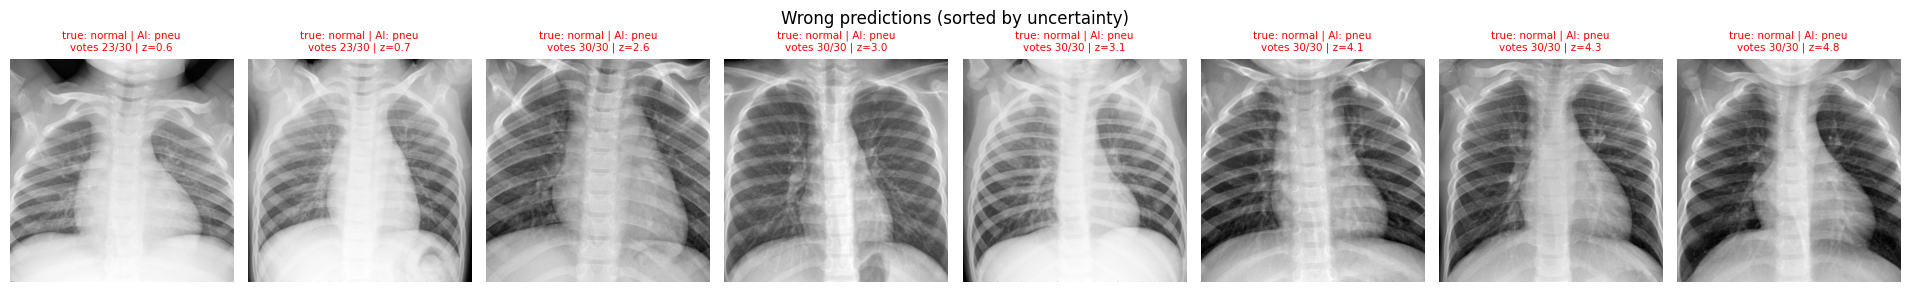

In [9]:
def show(indices, title, path):
    indices = list(indices)[:8]
    if not indices:
        print(f"(no images for: {title})"); return
    fig, axes = plt.subplots(1, len(indices), figsize=(2.4 * len(indices), 3))
    axes = np.atleast_1d(axes)
    for ax, i in zip(axes, indices):
        img = test_ds.imgs[i]
        ax.imshow(img, cmap="gray"); ax.axis("off")
        true = "pneu" if test_labels[i] == 1 else "normal"
        pred = "pneu" if test_s["pred"][i] == 1 else "normal"
        color = "green" if test_s["correct"][i] else "red"
        ax.set_title(f"true: {true} | AI: {pred}\nvotes {test_s['votes'][i]}/{T} | z={test_s['z'][i]:.1f}",
                     fontsize=7.5, color=color)
    plt.suptitle(title); plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

show(np.argsort(-test_s["z"]), "Most confident predictions", f"{FIG_DIR}/examples_confident.png")
show(np.argsort(test_s["z"]), "Most uncertain predictions (would be referred)", f"{FIG_DIR}/examples_uncertain.png")
show(np.where(errors)[0][np.argsort(test_s["z"][errors])], "Wrong predictions (sorted by uncertainty)", f"{FIG_DIR}/examples_errors.png")

## 8. Save the settings for the Streamlit app

In [10]:
config = {
    "model_file": "resnet18_baseline.pt",
    "mc_passes": T,
    "dropout": 0.3,
    "threshold_logit": THR_LOGIT,
    "threshold_prob": float(1 / (1 + np.exp(-THR_LOGIT))),
    "z_cutoff": Z_CUTOFF,
    "refer_rate_validation": REFER_RATE,
}
with open(os.path.join(SAVE_DIR, "trustxray_config.json"), "w") as f:
    json.dump(config, f, indent=2)
print(json.dumps(config, indent=2))

{
  "model_file": "resnet18_baseline.pt",
  "mc_passes": 30,
  "dropout": 0.3,
  "threshold_logit": -3.0871853828430176,
  "threshold_prob": 0.0436389510890049,
  "z_cutoff": 11.965063095092773,
  "refer_rate_validation": 0.1
}


## 9. Observations

- **Uncertainty detects errors:** median z = 23.0 for correct predictions vs 13.3 for errors; AUROC of the uncertainty score for detecting errors = 0.795.
- **Referral rule (fixed on validation, z < 11.97):** 105 / 624 test X-rays referred (16.8%). It catches 15 / 31 errors and **2 / 2 missed pneumonia cases**.
- **On the cases kept by the AI:** sensitivity 100% (0 missed pneumonia), accuracy 96.9%, false positives reduced from 29 to 16.
- **Distribution shift again:** the rule refers 10% of validation cases but 16.8% of test cases → the test set is more uncertain; radiologist workload estimated on validation would be underestimated.
- **Confident errors remain:** most remaining errors are normal X-rays predicted as pneumonia with 30/30 votes. Last-layer MC Dropout captures only part of the uncertainty, and the low threshold favors "pneumonia". Uncertainty is a safety net, not a guarantee.
- **Next step:** Grad-CAM — does the model look at the lungs, or at shortcuts (laterality markers, borders)?